# Session 3 — Deep dive: build a decision tree from scratch

*Teacher-run notebook. Run each cell live; the class predicts before every reveal.*

In class you asked the tree's questions and scored them. Now we **open the box and build the
whole machine ourselves** — on the real Titanic passengers — with **only numpy** (plus matplotlib
to draw). No scikit-learn, no pandas, no ready-made model. Everything (impurity, thresholds,
splits, the recursion, the stop rules and the pruning) is code **we** write.

> **Rule of the game:** at every stop, first **guess**; then run. The whole build is about
> 15 stops and fits in one sitting.

What we will build, in order:

1. the **three rulers** (misclassification · Gini · entropy) from raw label counts;
2. **scoring one question** — for a **continuous** feature (try every threshold) and for a
   **discrete** feature (one branch per value, ID3-style);
3. the **recursive tree** — score, take the winner, repeat inside each room;
4. **prediction** — route a new sample root→leaf, then the leaf's **majority vote**;
5. **the stopping strategies** — grow fully, then `max_depth`, `min_samples_leaf`,
   `min_samples_split`, `min_impurity_decrease`, and post-growth pruning.


## What "from scratch" means here

- **Allowed:** `numpy` (all the math), `matplotlib` (all the drawing), and the Python standard
  library (`csv` to read the file).
- **Not allowed:** any model library. We will not call `DecisionTreeClassifier` — we will *be*
  it. (At the very end there is a one-line note about the library, but no library is imported.)

The data is **real**: the Titanic passenger list, the same `assets/titanic.csv` used in class.


---

# Act 0 — put the real data on the table

This is not a toy. 891 real passengers, with missing values, mixed feature types (some
**discrete** like gender and class, some **continuous** like age and fare), and one label to
predict: **did this passenger survive?**


## Stop 0 — load the real passengers (no pandas)

We read the CSV with the standard library, keep the labelled columns, drop the rows that are
missing the values we use (so the number must match class: **712** passengers), and split the
features into the two kinds the tree treats differently:

- **continuous** → `age`, `fare` (a threshold carved out of a number line);
- **discrete** → `pclass`, `gender`, `embarked` (split by *which categories* go left).

**Predict:** how many of the 712 survived — closer to 300 or to 500?


In [1]:
# COURSE SETUP — we load the real file ourselves, with numpy and the standard library only.
%matplotlib inline
import csv, os, io, copy
import numpy as np
import matplotlib.pyplot as plt

def load_titanic():
    # real data: a local copy first, then the public URL as a fallback (class wifi is not a
    # dependency). No pandas — we parse the CSV with the standard library.
    for src in ("assets/titanic.csv", "../assets/titanic.csv"):
        if os.path.exists(src):
            text = open(src, encoding="utf-8").read()
            break
    else:
        import urllib.request
        url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
        with urllib.request.urlopen(url) as f:
            text = f.read().decode("utf-8")
    reader = csv.reader(io.StringIO(text))
    next(reader)                                   # skip the header row
    return list(reader)

# the shipped titanic.csv has a fixed column layout; we give the columns our own friendly names
COLUMNS = ["passenger_id", "survived", "pclass", "name", "gender", "age",
           "sibsp", "parch", "ticket", "fare", "cabin", "embarked"]

def build_dataset(rows):
    cols = {"pclass": [], "gender": [], "age": [], "fare": [], "embarked": []}
    y = []
    for raw in rows:
        r = dict(zip(COLUMNS, raw))
        try:
            survived = int(r["survived"]); pclass = int(r["pclass"]); gender = r["gender"].strip()
            age = float(r["age"]); fare = float(r["fare"]); embarked = r["embarked"].strip()
        except (ValueError, KeyError):
            continue          # a missing/odd value: drop the whole row (same as class)
        if embarked == "":
            continue
        cols["pclass"].append(pclass); cols["gender"].append(gender); cols["age"].append(age)
        cols["fare"].append(fare); cols["embarked"].append(embarked); y.append(survived)
    feats = {
        "pclass":   {"kind": "discrete",   "values": np.array(cols["pclass"], dtype=object)},
        "gender":   {"kind": "discrete",   "values": np.array(cols["gender"], dtype=object)},
        "embarked": {"kind": "discrete",   "values": np.array(cols["embarked"], dtype=object)},
        "age":      {"kind": "continuous", "values": np.array(cols["age"], dtype=float)},
        "fare":     {"kind": "continuous", "values": np.array(cols["fare"], dtype=float)},
    }
    return feats, np.array(y, dtype=int)

feats, y = build_dataset(load_titanic())
n = len(y)
print(f"passengers kept: {n}   (survived {int(y.sum())}, did not {int((1 - y).sum())})")
print()
print("the first 5 real passengers, as the tree sees them:")
print(f"{'pclass':>6} {'gender':>7} {'age':>5} {'fare':>8} {'embarked':>9} | survived")
for i in range(5):
    row = [feats[k]["values"][i] for k in ("pclass", "gender", "age", "fare", "embarked")]
    print(f"{row[0]:>6} {row[1]:>7} {row[2]:>5.1f} {row[3]:>8.2f} {row[4]:>9} | {int(y[i])}")
print()
print("continuous features:", [k for k, f in feats.items() if f["kind"] == "continuous"])
print("discrete features:  ", [k for k, f in feats.items() if f["kind"] == "discrete"])


passengers kept: 712   (survived 288, did not 424)

the first 5 real passengers, as the tree sees them:
pclass  gender   age     fare  embarked | survived
     3    male  22.0     7.25         S | 0
     1  female  38.0    71.28         C | 1
     3  female  26.0     7.92         S | 1
     1  female  35.0    53.10         S | 1
     3    male  35.0     8.05         S | 0

continuous features: ['age', 'fare']
discrete features:   ['pclass', 'gender', 'embarked']


---

# Act I — the three rulers, from raw counts

A tree can only start if it can measure one thing: **how mixed is a box of labels?**
In class we called this **impurity**. We now write the three rulers ourselves.


## Stop 1 — misclassification, Gini, entropy (from counts only)

All three are computed from one input: the **counts** of each label in the box.

| ruler | the kid-words meaning | formula (from the counts) |
|---|---|---|
| **misclassification** | the share you would get wrong by always guessing the majority | `1 − max_p` |
| **Gini** | the chance two random draws disagree | `1 − Σ p²` |
| **entropy** | the expected number of yes/no questions to reveal a draw (bits) | `−Σ p·log2(p)` |

**Predict:** for a box of 8 blue — what do all three say? And for a box of 4 blue + 4 red?


In [2]:
# Stop 1 — the three rulers, computed straight from label counts.
def _counts(labels):
    values, counts = np.unique(labels, return_counts=True)
    return counts / counts.sum()

def misclassification(labels):
    # how often the majority guess would be wrong
    return float(1.0 - _counts(labels).max())

def gini(labels):
    # the chance two blind draws give different labels
    p = _counts(labels)
    return float(1.0 - (p ** 2).sum())

def entropy(labels):
    # the expected number of yes/no questions to reveal a draw (bits)
    p = _counts(labels)
    e = float(-(p * np.log2(p)).sum())
    return 0.0 if e <= 0 else e            # keep a pure box at exactly 0 (not -0.0)

# the three bags from class, as raw label lists
bags = {
    "8 blue":             ["blue"] * 8,
    "4 blue + 4 red":     ["blue"] * 4 + ["red"] * 4,
    "3 blue + 3 red + 2 green": ["blue"] * 3 + ["red"] * 3 + ["green"] * 2,
}
print(f"{'bag':<26} {'misclass':>9} {'gini':>7} {'entropy':>8}")
for name, bag in bags.items():
    print(f"{name:<26} {misclassification(bag):>9.2f} {gini(bag):>7.2f} {entropy(bag):>8.2f}")
print()
print("pure -> 0 for every ruler. The three agree in ORDER: 0  <  0.5/1.0  <  0.66/1.56")


bag                         misclass    gini  entropy
8 blue                          0.00    0.00     0.00
4 blue + 4 red                  0.50    0.50     1.00
3 blue + 3 red + 2 green        0.62    0.66     1.56

pure -> 0 for every ruler. The three agree in ORDER: 0  <  0.5/1.0  <  0.66/1.56


## Stop 2 — the whole Titanic box, measured

Now the real thing: one box holding all 712 labels.

**Predict:** is the ship closer to "very mixed" (near 0.5) or "almost sorted" (near 0)?


In [3]:
# Stop 2 — impurity of the entire Titanic box.
print(f"the whole box: gini {gini(y):.3f}   entropy {entropy(y):.3f} bits   "
      f"misclassification {misclassification(y):.3f}")
print(f"(that matches class: Gini 0.482, entropy 0.974)")
print()
print("the box is fairly mixed - lots of room for a good question to help.")


the whole box: gini 0.482   entropy 0.974 bits   misclassification 0.404
(that matches class: Gini 0.482, entropy 0.974)

the box is fairly mixed - lots of room for a good question to help.


## Stop 3 — the rulers agree (see it)

Make a box that is "blue with probability p". Sweep p from 0 to 1 and plot Gini and entropy.
They peak at **p = 0.5** (maximally mixed) and touch **0** at the pure ends.


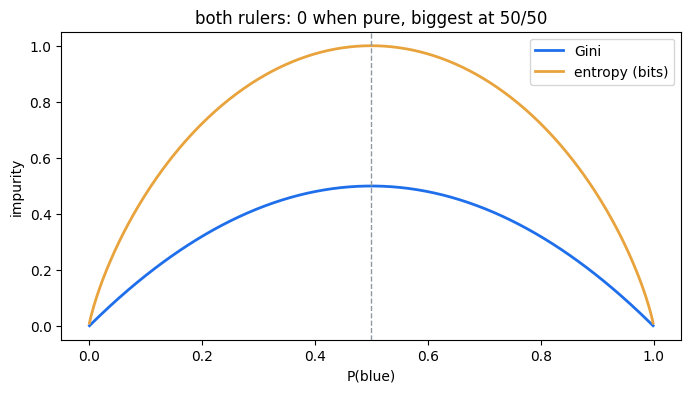

same shape, same order, different unit. Gini is the grey-area chance;
entropy counts the yes/no questions. We will use one of them to score splits.


In [4]:
# Stop 3 - the two rulers over every "how blue is it?" box
p = np.linspace(0.001, 0.999, 400)
gini_curve = 1 - (p ** 2 + (1 - p) ** 2)
ent_curve = -(p * np.log2(p) + (1 - p) * np.log2(1 - p))
plt.figure(figsize=(8, 4))
plt.plot(p, gini_curve, color="#1F6FEB", lw=2, label="Gini")
plt.plot(p, ent_curve, color="#E8A33D", lw=2, label="entropy (bits)")
plt.axvline(0.5, color="#9099A1", ls="--", lw=1)
plt.xlabel("P(blue)"); plt.ylabel("impurity")
plt.title("both rulers: 0 when pure, biggest at 50/50"); plt.legend()
plt.show()
print("same shape, same order, different unit. Gini is the grey-area chance;")
print("entropy counts the yes/no questions. We will use one of them to score splits.")


---

# Act II — score one question

A question splits the box in two. Its **score (information gain)** is:

```
gain  =  impurity(before)  -  impurity(after)
```

where `impurity(after)` is the **weighted** average of the two sides, each weighted by **its own
size** (the big side matters more). We now look for the *best* question of each kind.


## Stop 4 — a continuous feature: try every threshold

For a number like `age`, a question is "**is age ≤ t?**". There are infinitely many `t`, but
only the **midpoints between the sorted values** can change anything. We try them all and keep
the one with the biggest gain — and we print the table so nothing is hidden.

**Predict:** the best age split — a low age (children first) or a high age?


In [5]:
# Stop 4 — best threshold for a continuous feature (here: age)
def split_gain_continuous(values, labels, t):
    left = values <= t
    nl, nr = left.sum(), (~left).sum()
    if nl == 0 or nr == 0:
        return None
    after = (nl * gini(labels[left]) + nr * gini(labels[~left])) / len(labels)
    return gini(labels) - after, after

def best_continuous(values, labels, metric=gini):
    order = np.argsort(values, kind="mergesort")
    xs = values[order]
    mid = (xs[:-1] + xs[1:]) / 2.0
    mid = mid[xs[:-1] != xs[1:]]              # only where the value actually changes
    base = metric(labels)
    rows = []
    for t in np.unique(mid):
        left = values <= t
        nl, nr = left.sum(), (~left).sum()
        if nl == 0 or nr == 0:
            continue
        after = (nl * metric(labels[left]) + nr * metric(labels[~left])) / len(labels)
        rows.append((float(t), nl, nr, after, base - after))
    rows.sort(key=lambda r: r[4], reverse=True)
    return rows

age_rows = best_continuous(feats["age"]["values"], y)
print("age — the 8 best thresholds (of %d tried):" % len(age_rows))
print(f"{'threshold':>10} {'left n':>7} {'right n':>8} {'after':>7} {'gain':>7}")
for t, nl, nr, after, gain in age_rows[:8]:
    print(f"{t:>10.1f} {nl:>7d} {nr:>8d} {after:>7.3f} {gain:>7.4f}")
print("best age question:", f"age <= {age_rows[0][0]:.1f}", "-> gain", round(age_rows[0][4], 4))


age — the 8 best thresholds (of 87 tried):
 threshold  left n  right n   after    gain
       6.5      47      665   0.469  0.0125
       5.5      44      668   0.470  0.0119
       7.5      50      662   0.470  0.0115
       8.5      54      658   0.470  0.0113
      15.5      83      629   0.473  0.0091
       4.5      40      672   0.473  0.0087
       9.5      62      650   0.473  0.0083
       1.5      14      698   0.474  0.0082
best age question: age <= 6.5 -> gain 0.0125


## Stop 5 — a discrete feature: one branch per value

For a category like `embarked` (C, Q, S) the classic ID3 question is simply "**which value is
it?**" — and the node gets **one branch per value**: three children, not two. (A two-valued
feature like `gender` makes just two branches, so there the conventions coincide.)

The gain follows the same recipe as always: `impurity before − the weighted average of the
branches`, each branch weighted by **its own size**. We print every branch so nothing is hidden.

**Predict:** `embarked` (3 values) will make how many branches — and will it beat `gender`?


In [6]:
# Stop 5 — split a discrete feature into one branch per value (ID3-style multiway)
def discrete_branches(values, labels):
    # the categories present here, and the mask of rows that fall into each branch
    return {v: values == v for v in np.unique(values)}

def discrete_gain(values, labels, metric=gini):
    base = metric(labels)
    rows, after = [], 0.0
    for v, mask in discrete_branches(values, labels).items():
        branch = labels[mask]
        weight = mask.sum() / len(labels)          # this branch's share of the node
        after += weight * metric(branch)
        rows.append((v, int(mask.sum()), weight, metric(branch), weight * metric(branch)))
    return base - after, after, rows

def show_discrete(name):
    gain, after, rows = discrete_gain(feats[name]["values"], y)
    print(f"{name} — one branch per value ({len(rows)} branches):")
    print(f"{'branch':<8}{'n':>6}{'weight':>8}{'impurity':>10}{'w x imp':>10}")
    for v, n, w, imp, wi in rows:
        print(f"{str(v):<8}{n:>6}{w:>8.3f}{imp:>10.3f}{wi:>10.3f}")
    print(f"{'after':<8}{'':>6}{'':>8}{after:>10.3f}   gain = {gain:.4f}")
    print()

show_discrete("embarked")
show_discrete("pclass")
show_discrete("gender")


embarked — one branch per value (3 branches):
branch       n  weight  impurity   w x imp
C          130   0.183     0.477     0.087
Q           28   0.039     0.408     0.016
S          554   0.778     0.462     0.360
after                      0.463   gain = 0.0189

pclass — one branch per value (3 branches):
branch       n  weight  impurity   w x imp
1          184   0.258     0.454     0.117
2          173   0.243     0.499     0.121
3          355   0.499     0.364     0.182
after                      0.420   gain = 0.0616

gender — one branch per value (2 branches):
branch       n  weight  impurity   w x imp
female     259   0.364     0.372     0.135
male       453   0.636     0.326     0.208
after                      0.343   gain = 0.1388



## Stop 6 — the leaderboard: which feature wins the root?

Every feature proposes its best question — a **threshold** for a continuous feature, a
**one-branch-per-value** split for a discrete one — and the biggest gain wins. That is the
**first question** of the tree.

**Predict:** which wins on Titanic — `gender`, `pclass`, `fare`, `age` or `embarked`?


In [7]:
# Stop 6 — score every feature, show the leaderboard
def best_question(feats, labels, metric=gini):
    scores = {}
    for name, f in feats.items():
        if f["kind"] == "continuous":
            rows = best_continuous(f["values"], labels, metric)
            t, nl, nr, after, gain = rows[0]
            scores[name] = ("continuous", 2, f"<= {t:.1f}", gain, after)
        else:
            gain, after, rows = discrete_gain(f["values"], labels, metric)
            cats = "{" + ", ".join(str(c) for c in sorted(np.unique(f["values"]))) + "}"
            scores[name] = ("discrete", len(rows), f"one branch per value {cats}", gain, after)
    return scores

scores = best_question(feats, y)
print(f"{'feature':<10} {'kind':<11} {'branches':>9} {'gain':>8}  the question")
for name, (kind, nb, q, gain, after) in sorted(scores.items(), key=lambda kv: kv[1][3], reverse=True):
    print(f"{name:<10} {kind:<11} {nb:>9} {gain:>8.4f}  {q}")
print()
print("the winner is the tree's first question — and it is 'gender', gain 0.139, like class.")
print("(`gender` has two values, so it is identical in both conventions; the multi-branch")
print(" features score a touch higher than the class's two-group leaderboard.)")


feature    kind         branches     gain  the question
gender     discrete            2   0.1388  one branch per value {female, male}
pclass     discrete            3   0.0616  one branch per value {1, 2, 3}
fare       continuous          2   0.0455  <= 52.3
embarked   discrete            3   0.0189  one branch per value {C, Q, S}
age        continuous          2   0.0125  <= 6.5

the winner is the tree's first question — and it is 'gender', gain 0.139, like class.
(`gender` has two values, so it is identical in both conventions; the multi-branch
 features score a touch higher than the class's two-group leaderboard.)


---

# Act III — grow the tree

The whole secret is **one loop**: score every question, take the winner, then do it **again
inside each room**. A threshold makes **two** rooms; a category makes **one room per value**.
Recursion does the "again" for us.


## Stop 7 — the recursion (with a printed growth trace)

Each node becomes a **leaf** (if it is pure, or no question helps, or a stop rule fires) or a
**split** (the best question found): a threshold gives **two** children, a category gives **one
child per value**. We grow a **depth-3** tree on the training rows and print every decision as
it is made — nothing hidden.

**Predict:** after the first question (`gender`), which feature shows up in the next rooms?


In [8]:
# Stop 7 — the recursive builder, with a trace of every node it makes
def make_leaf(labels):
    values, counts = np.unique(labels, return_counts=True)
    return {"leaf": True, "n": int(len(labels)), "impurity": gini(labels),
            "vote": int(values[np.argmax(counts)]),
            "counts": {int(v): int(c) for v, c in zip(values, counts)}}

def build(feats, full_labels, idx, depth, metric=gini, params=None, trace=None):
    params = params or {}
    box = full_labels[idx]                        # the labels that reached this node
    node = make_leaf(box)
    node["depth"] = depth
    if trace is not None:
        trace.append("  " * depth + f"depth {depth} | n={node['n']:>4} | impurity {node['impurity']:.3f} | "
                     f"counts {node['counts']}")

    # ---- the stop rules (Act IV sets the knobs; here depth is capped at 3) ----
    if node["impurity"] == 0.0:
        if trace is not None: trace.append(f"{' ' * depth * 2}-> PURE: make a leaf (vote {node['vote']})")
        return node
    if params.get("max_depth") is not None and depth >= params["max_depth"]:
        if trace is not None: trace.append(f"{' ' * depth * 2}-> max_depth reached: make a leaf")
        return node
    if node["n"] < params.get("min_samples_split", 2):
        if trace is not None: trace.append(f"{' ' * depth * 2}-> too few samples: make a leaf")
        return node

    # ---- score every question and take the winner ----
    overall = which_feature = which_kind = which_split = None
    for name, f in feats.items():
        if f["kind"] == "continuous":
            rows = best_continuous(f["values"][idx], box, metric)
            if not rows: continue
            gain, cand_kind, cand_split = rows[0][4], "continuous", rows[0][0]
        else:
            gain, after, rows = discrete_gain(f["values"][idx], box, metric)
            if len(rows) < 2: continue          # only one value here -> cannot split
            cand_kind, cand_split = "discrete", None
        if overall is None or gain > overall:
            overall, which_feature, which_kind, which_split = gain, name, cand_kind, cand_split

    if overall is None or overall < params.get("min_impurity_decrease", 0.0):
        if trace is not None: trace.append(f"{' ' * depth * 2}-> no useful question: make a leaf")
        return node

    # ---- the children: TWO for a threshold, ONE PER VALUE for a category ----
    values_here = feats[which_feature]["values"][idx]
    if which_kind == "continuous":
        branches = {"left": values_here <= which_split, "right": values_here > which_split}
        q = f"<= {which_split:.1f}"
    else:
        branches = {v: values_here == v for v in np.unique(values_here)}
        q = "one branch per value {" + ", ".join(str(v) for v in sorted(branches)) + "}"

    if min(m.sum() for m in branches.values()) < params.get("min_samples_leaf", 1):
        if trace is not None: trace.append(f"{' ' * depth * 2}-> would make a tiny leaf: refuse")
        return node

    if trace is not None:
        trace.append(f"{' ' * depth * 2}ASK  {which_feature}: {q}   "
                     f"({len(branches)} branch(es) | gain {overall:.4f}, "
                     f"impurity {node['impurity']:.3f} -> {metric(box) - overall:.3f})")

    split_node = {"leaf": False, "n": node["n"], "impurity": node["impurity"], "depth": depth,
                  "feature": which_feature, "kind": which_kind, "gain": overall,
                  "after": metric(box) - overall, "vote": node["vote"], "counts": node["counts"]}
    if which_kind == "continuous":
        split_node["split"] = which_split
        split_node["left"] = build(feats, full_labels, idx[branches["left"]], depth + 1, metric, params, trace)
        split_node["right"] = build(feats, full_labels, idx[branches["right"]], depth + 1, metric, params, trace)
    else:
        split_node["groups"] = list(branches.keys())
        split_node["children"] = {v: build(feats, full_labels, idx[mask], depth + 1, metric, params, trace)
                                  for v, mask in branches.items()}
    return split_node

# a 70/30 train/test split, done by hand and STRATIFIED (same survival ratio in both halves)
def stratified_split(labels, seed, test_frac=0.3):
    rng = np.random.default_rng(seed)
    test_parts = []
    for cls in np.unique(labels):
        idx = np.where(labels == cls)[0]
        idx = idx[rng.permutation(len(idx))]
        test_parts.append(idx[:int(round(len(idx) * test_frac))])
    test_idx = np.concatenate(test_parts)
    train_idx = np.setdiff1d(np.arange(len(labels)), test_idx)
    return train_idx, test_idx

train_idx, test_idx = stratified_split(y, seed=42)
print(f"training rows: {len(train_idx)}   test rows: {len(test_idx)}")
print(f"survival rate kept close -> train {y[train_idx].mean():.3f} | test {y[test_idx].mean():.3f}\n")

trace = []
tree = build(feats, y, train_idx, 0, gini, {"max_depth": 3}, trace)
for line in trace:
    print(line)


training rows: 499   test rows: 213
survival rate kept close -> train 0.405 | test 0.404



depth 0 | n= 499 | impurity 0.482 | counts {0: 297, 1: 202}
ASK  gender: one branch per value {female, male}   (2 branch(es) | gain 0.1201, impurity 0.482 -> 0.362)
  depth 1 | n= 183 | impurity 0.397 | counts {0: 50, 1: 133}
  ASK  pclass: one branch per value {1, 2, 3}   (3 branch(es) | gain 0.1363, impurity 0.397 -> 0.261)
    depth 2 | n=  57 | impurity 0.100 | counts {0: 3, 1: 54}
    ASK  age: <= 8.0   (2 branch(es) | gain 0.0321, impurity 0.100 -> 0.068)
      depth 3 | n=   1 | impurity 0.000 | counts {0: 1}
      -> PURE: make a leaf (vote 0)
      depth 3 | n=  56 | impurity 0.069 | counts {0: 2, 1: 54}
      -> max_depth reached: make a leaf
    depth 2 | n=  54 | impurity 0.137 | counts {0: 4, 1: 50}
    ASK  age: <= 55.5   (2 branch(es) | gain 0.0324, impurity 0.137 -> 0.105)
      depth 3 | n=  53 | impurity 0.107 | counts {0: 3, 1: 50}
      -> max_depth reached: make a leaf
      depth 3 | n=   1 | impurity 0.000 | counts {0: 1}
      -> PURE: make a leaf (vote 0)
    d

## Stop 8 — read the tree

We can draw the same tree as indented text: each line is a question (with its gain and how many
rows reached it), and each `-> leaf` line shows the **majority vote** it will answer with.

**Predict:** the deepest leaves on the "died" side — are they pure (all died) or still mixed?


In [9]:
# Stop 8 - print the tree as an indented outline
def n_leaves(node):
    if node["leaf"]:
        return 1
    if node["kind"] == "continuous":
        return n_leaves(node["left"]) + n_leaves(node["right"])
    return sum(n_leaves(child) for child in node["children"].values())

def depth_of(node):
    if node["leaf"]:
        return 0
    if node["kind"] == "continuous":
        return 1 + max(depth_of(node["left"]), depth_of(node["right"]))
    return 1 + max(depth_of(child) for child in node["children"].values())

def print_tree(node, indent=0):
    pad = "    " * indent
    if node["leaf"]:
        print(f"{pad}-> leaf: vote={'survived' if node['vote'] else 'died'}   "
              f"n={node['n']}   counts={node['counts']}")
    elif node["kind"] == "continuous":
        print(f"{pad}[{node['feature']} <= {node['split']:.1f}]   n={node['n']}   gain={node['gain']:.4f}")
        print_tree(node["left"], indent + 1)
        print_tree(node["right"], indent + 1)
    else:
        print(f"{pad}[{node['feature']}: one branch per value]   n={node['n']}   gain={node['gain']:.4f}")
        for value, child in node["children"].items():
            print(f"{pad}    -- {node['feature']} = {value} --")
            print_tree(child, indent + 2)

print_tree(tree)
print(f"\nleaves: {n_leaves(tree)}   depth: {depth_of(tree)}")


[gender: one branch per value]   n=499   gain=0.1201
    -- gender = female --
        [pclass: one branch per value]   n=183   gain=0.1363
            -- pclass = 1 --
                [age <= 8.0]   n=57   gain=0.0321
                    -> leaf: vote=died   n=1   counts={0: 1}
                    -> leaf: vote=survived   n=56   counts={0: 2, 1: 54}
            -- pclass = 2 --
                [age <= 55.5]   n=54   gain=0.0324
                    -> leaf: vote=survived   n=53   counts={0: 3, 1: 50}
                    -> leaf: vote=died   n=1   counts={0: 1}
            -- pclass = 3 --
                [fare <= 19.7]   n=72   gain=0.0705
                    -> leaf: vote=survived   n=52   counts={0: 25, 1: 27}
                    -> leaf: vote=died   n=20   counts={0: 18, 1: 2}
    -- gender = male --
        [fare <= 26.3]   n=316   gain=0.0228
            [age <= 13.5]   n=218   gain=0.0549
                -> leaf: vote=survived   n=12   counts={0: 2, 1: 10}
                -> leaf

## Stop 9 — prediction: route, then vote

To decide for a **new** passenger: start at the root, ask each question on its features, follow
the matching branch until a **leaf**, then answer with the leaf's **majority vote**. A threshold
sends you left or right; a category sends you to the branch for its own value.

**Predict:** a first-class 30-year-old woman — survives or not, and by which path?


In [10]:
# Stop 9 - route one passenger down the tree, then read the leaf's vote
def predict_one(node, x):
    path = []
    while not node["leaf"]:
        v = x[node["feature"]]
        if node["kind"] == "continuous":
            go_left = v <= node["split"]
            path.append(f"{node['feature']} = {v} <= {node['split']:.1f}? -> {'yes' if go_left else 'no'}")
            node = node["left"] if go_left else node["right"]
        else:
            path.append(f"{node['feature']} = {v}  ->  branch '{v}'")
            if v not in node["children"]:      # a value never seen while training
                path.append(f"(no branch for '{v}' -> fall back to this node's vote {node['vote']})")
                return node["vote"], path, node
            node = node["children"][v]
    return node["vote"], path, node

def predict(node, feats, idx):
    out = np.zeros(len(idx), dtype=int)
    for i, row in enumerate(idx):
        x = {name: feats[name]["values"][row] for name in feats}
        out[i] = predict_one(node, x)[0]
    return out

new_passenger = {"pclass": 1, "gender": "female", "age": 30.0, "fare": 80.0, "embarked": "S"}
vote, path, leaf = predict_one(tree, new_passenger)
print("a first-class 30-year-old woman:")
for step in path:
    print("   ", step)
print(f"-> the leaf votes: {'survived' if vote else 'died'}"
      f"   (leaf n={leaf['n']}, counts={leaf['counts']})")
print()
train_acc = (predict(tree, feats, train_idx) == y[train_idx]).mean()
print(f"training accuracy of this hand-built tree: {train_acc:.3f}")


a first-class 30-year-old woman:
    gender = female  ->  branch 'female'
    pclass = 1  ->  branch '1'
    age = 30.0 <= 8.0? -> no
-> the leaf votes: survived   (leaf n=56, counts={0: 2, 1: 54})

training accuracy of this hand-built tree: 0.820


---

# Act IV — the stopping strategies

The loop above only stopped because we capped it at depth 3. Left alone, a tree grows until every
training row sits in its own leaf — and then it **memorizes** instead of learning.


## Stop 10 — grow it fully and watch it memorize

Same builder, **no cap**. On the training rows it can be near-perfect; on rows it has never seen
it does worse. (This is the fever Session 4 named.)

**Predict:** training accuracy when nothing stops the tree — 90% or 99%?


In [11]:
# Stop 10 - no limit: the tree memorizes the training rows
def train_test_acc(node):
    tr = (predict(node, feats, train_idx) == y[train_idx]).mean()
    te = (predict(node, feats, test_idx) == y[test_idx]).mean()
    return tr, te

full_tree = build(feats, y, train_idx, 0, gini, {})
tr, te = train_test_acc(full_tree)
print(f"unlimited tree: leaves {n_leaves(full_tree):3d} | train {tr:.3f} | test {te:.3f} | gap {tr - te:.3f}")
print("near-perfect on the rows it studied, worse on the rows it never saw - it memorized noise.")


unlimited tree: leaves 131 | train 0.988 | test 0.775 | gap 0.213
near-perfect on the rows it studied, worse on the rows it never saw - it memorized noise.


## Stop 11 — `max_depth`: stop earlier

If we only let the tree ask at most `d` questions down a path, it cannot make a private leaf for
every odd row. We sweep `d`, and watch the training score climb while the test score peaks and
turns — the overfitting curve, but now **we** produced it.

A single split is noisy (that is Session 6's whole point), so we repeat the sweep on **20
different splits and average** — the honest curve.

**Predict:** at which depth is the averaged test score best?


averaged over 20 different splits:
max_depth   train    test
        2   0.798   0.792
        4   0.847   0.803
        6   0.886   0.794
        8   0.921   0.783
       10   0.950   0.773
       12   0.969   0.769

best test score at depth 4: 0.803


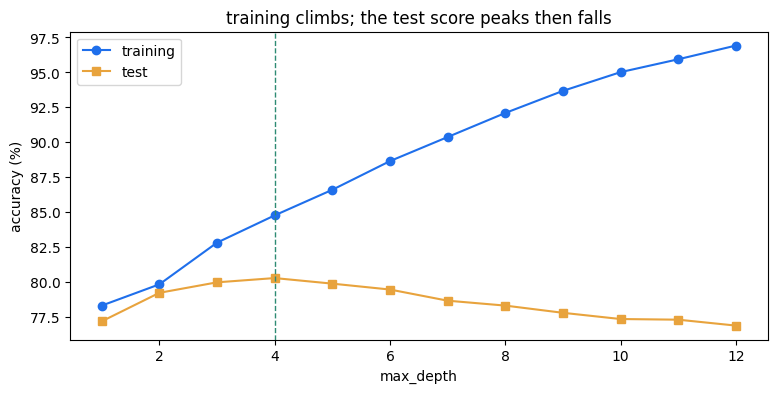

one split is noisy - averaging several is the honest way (that is Session 6).


In [12]:
# Stop 11 - one split is noisy, so repeat the whole sweep on many splits and average
depths = list(range(1, 13))
NSPLITS = 20
train_curve = np.zeros(len(depths))
test_curve = np.zeros(len(depths))
for seed in range(NSPLITS):
    tr_i, te_i = stratified_split(y, seed=seed)
    for j, d in enumerate(depths):
        t = build(feats, y, tr_i, 0, gini, {"max_depth": d})
        train_curve[j] += (predict(t, feats, tr_i) == y[tr_i]).mean()
        test_curve[j] += (predict(t, feats, te_i) == y[te_i]).mean()
train_curve /= NSPLITS
test_curve /= NSPLITS

best_d = depths[int(np.argmax(test_curve))]
print(f"averaged over {NSPLITS} different splits:")
print(f"{'max_depth':>9} {'train':>7} {'test':>7}")
for j, d in enumerate(depths):
    if d % 2 == 0 or d == best_d:
        print(f"{d:>9} {train_curve[j]:>7.3f} {test_curve[j]:>7.3f}")
print(f"\nbest test score at depth {best_d}: {max(test_curve):.3f}")

plt.figure(figsize=(9, 4))
plt.plot(depths, 100 * train_curve, "o-", color="#1F6FEB", label="training")
plt.plot(depths, 100 * test_curve, "s-", color="#E8A33D", label="test")
plt.axvline(best_d, color="#2E8B74", ls="--", lw=1)
plt.xlabel("max_depth"); plt.ylabel("accuracy (%)")
plt.title("training climbs; the test score peaks then falls"); plt.legend()
plt.show()
print("one split is noisy - averaging several is the honest way (that is Session 6).")


## Stop 12 — three more dials (all just numbers in the stop rules)

The builder already honours them; we only set the numbers.

| dial | stop when… |
|---|---|
| `min_samples_split` | a node has fewer than this many rows → make it a leaf |
| `min_samples_leaf` | a question would make a side smaller than this → refuse the split |
| `min_impurity_decrease` | the best gain is smaller than this → not worth asking |

**Predict:** which dial will produce the **smallest** tree — forcing big leaves, or demanding a
minimum gain?


In [13]:
# Stop 12 - compare the three pre-pruning dials on the test set
settings = {
    "max_depth=4":              {"max_depth": 4},
    "min_samples_leaf=10":      {"min_samples_leaf": 10},
    "min_samples_split=30":     {"min_samples_split": 30},
    "min_impurity_decrease=0.02": {"min_impurity_decrease": 0.02},
}
print(f"{'setting':<28} {'leaves':>7} {'train':>7} {'test':>7}")
for name, params in settings.items():
    t = build(feats, y, train_idx, 0, gini, params)
    tr, te = train_test_acc(t)
    print(f"{name:<28} {n_leaves(t):>7d} {tr:>7.3f} {te:>7.3f}")
print()
print("each dial shrinks the tree in a different way; the honest judge is always the test set.")


setting                       leaves   train    test


max_depth=4                       17   0.836   0.822
min_samples_leaf=10                9   0.810   0.836


min_samples_split=30              44   0.860   0.803


min_impurity_decrease=0.02        37   0.878   0.836

each dial shrinks the tree in a different way; the honest judge is always the test set.


---

# Act V — stop *after* growth: pruning

Sometimes the best split early looks weak, but a great split hides under it. So instead of
stopping early, we grow the whole tree, then **cut the weakest branches** — cost-complexity
pruning. A branch is "weak" when it removes very little impurity for the number of leaves it adds.


## Stop 13 — the weakest-link pruning, then choose on a validation slice

For every internal node we compute its **effective alpha**:

```
alpha =  (impurity_the_node_would_have_as_a_leaf  -  impurity_of_its_whole_subtree)
         -------------------------------------------------------------------------------
                          (number_of_leaves_in_that_subtree  -  1)
```

We repeatedly cut the node with the **smallest** alpha, recording the whole path. Then we pick the
cut whose tree scores best on a **validation** slice (never the test set — that would be studying
the exam). The winner is a much smaller tree that matches or beats the giant.

**Predict:** after pruning, roughly how many leaves survive — hundreds, or a handful?


In [14]:
# Stop 13 - grow fully, then prune the weakest link; choose alpha on a validation slice
# (grow on a training slice, keep a validation slice of it, judge the result once on the test set)
rng2 = np.random.default_rng(7)
inner = rng2.permutation(len(train_idx))
cut2 = int(len(inner) * 0.75)
grow_idx, val_idx = train_idx[inner[:cut2]], train_idx[inner[cut2:]]

def subtree_leaves(node):
    if node["leaf"]:
        return 1
    if node["kind"] == "continuous":
        return subtree_leaves(node["left"]) + subtree_leaves(node["right"])
    return sum(subtree_leaves(child) for child in node["children"].values())

def subtree_risk(node, N):
    if node["leaf"]:
        return node["impurity"] * node["n"] / N
    if node["kind"] == "continuous":
        return subtree_risk(node["left"], N) + subtree_risk(node["right"], N)
    return sum(subtree_risk(child, N) for child in node["children"].values())

def collect(node, path=()):
    yield path, node
    if node["leaf"]:
        return
    if node["kind"] == "continuous":
        yield from collect(node["left"], path + (("L", None),))
        yield from collect(node["right"], path + (("R", None),))
    else:
        for value, child in node["children"].items():
            yield from collect(child, path + (("C", value),))

def node_at(node, path):
    for step, value in path:
        if step == "L":
            node = node["left"]
        elif step == "R":
            node = node["right"]
        else:
            node = node["children"][value]
    return node

def replace_at(node, path, value):
    parent = node_at(node, path[:-1])
    step, branch = path[-1]
    if step == "L":
        parent["left"] = value
    elif step == "R":
        parent["right"] = value
    else:
        parent["children"][branch] = value

def weakest_alpha(root, N):
    best = None
    for path, node in collect(root):
        if node["leaf"] or len(path) == 0:
            continue
        leaves = subtree_leaves(node)
        alpha = (node["impurity"] * node["n"] / N - subtree_risk(node, N)) / (leaves - 1)
        if best is None or alpha < best[0] - 1e-12:
            best = (alpha, path)
    return best

def pruning_path(root, N):
    work = copy.deepcopy(root)
    alphas, trees = [0.0], [copy.deepcopy(work)]
    while True:
        cut = weakest_alpha(work, N)
        if cut is None:
            break
        alpha, path = cut
        node = node_at(work, path)
        replace_at(work, path, {"leaf": True, "n": node["n"], "impurity": node["impurity"],
                                "vote": node["vote"], "counts": node["counts"]})
        alphas.append(alpha); trees.append(copy.deepcopy(work))
    return alphas, trees

big = build(feats, y, grow_idx, 0, gini, {})
N = len(grow_idx)
print(f"grown on the training slice: leaves {n_leaves(big)} | "
      f"validation acc {(predict(big, feats, val_idx) == y[val_idx]).mean():.3f}")

alphas, trees = pruning_path(big, N)
print(f"pruning path: {len(trees)} trees, alpha from 0.0 up to {alphas[-1]:.4f}\n")
print(f"{'ccp_alpha':>10} {'leaves':>7} {'valid acc':>10}")
best = None
for alpha, t in zip(alphas, trees):
    v = (predict(t, feats, val_idx) == y[val_idx]).mean()
    if best is None or v > best[1] + 1e-12:
        best = (alpha, v, t)
for alpha, t in list(zip(alphas, trees))[::6] + [(best[0], best[2])]:
    print(f"{alpha:>10.4f} {n_leaves(t):>7d} {(predict(t, feats, val_idx) == y[val_idx]).mean():>10.3f}")

pruned = best[2]
print(f"\nbest on validation: ccp_alpha={best[0]:.4f} -> {n_leaves(pruned)} leaves")
print(f"pruned tree  : train {train_test_acc(pruned)[0]:.3f} | test {train_test_acc(pruned)[1]:.3f}")
print(f"unpruned tree: train {train_test_acc(big)[0]:.3f} | test {train_test_acc(big)[1]:.3f}")
print("a handful of leaves beats the giant - pruning wins.")


grown on the training slice: leaves 103 | validation acc 0.824
pruning path: 37 trees, alpha from 0.0 up to 0.0314

 ccp_alpha  leaves  valid acc
    0.0000     103      0.824
    0.0019      75      0.824
    0.0023      51      0.800
    0.0026      38      0.824
    0.0036      26      0.840
    0.0050      13      0.776
    0.0314       2      0.792
    0.0034      31      0.840

best on validation: ccp_alpha=0.0034 -> 31 leaves
pruned tree  : train 0.888 | test 0.826
unpruned tree: train 0.950 | test 0.779
a handful of leaves beats the giant - pruning wins.


---

# Act VI — your move


## Stop 14 — your own passenger

Pick any values, **predict before running**, then watch which rule your passenger obeyed.

(And a note, no library imported: scikit-learn's `DecisionTreeClassifier` is the same idea, with
one deliberate difference — it always makes **two** branches (the CART convention), whereas we
chose ID3-style **one branch per value**. For `gender` they agree exactly; for `pclass`/`embarked`
ours grows a wider node. Now you know what is inside either one.)


In [15]:
# Stop 14 - your passenger
mine = {"pclass": 2, "gender": "female", "age": 9.0, "fare": 21.0, "embarked": "S"}
vote, path, leaf = predict_one(tree, mine)
print("your passenger:", mine)
for step in path:
    print("   ", step)
print(f"-> {'survived' if vote else 'did not survive'}"
      f"   (leaf counts {leaf['counts']})")
print()
print("why? which of the tree's rules did your passenger follow?")


your passenger: {'pclass': 2, 'gender': 'female', 'age': 9.0, 'fare': 21.0, 'embarked': 'S'}
    gender = female  ->  branch 'female'
    pclass = 2  ->  branch '2'
    age = 9.0 <= 55.5? -> yes
-> survived   (leaf counts {0: 3, 1: 50})

why? which of the tree's rules did your passenger follow?


## Where this comes from (the books)

The machine we built is not improvised — it is the classic decision-tree algorithm, and the
course's books say so (verbatim):

- **Information gain:** “The measure we will use, called information gain, is simply the
  expected reduction in entropy caused by partitioning the examples according to this
  attribute.” — Mitchell, *Machine Learning*, §3.4.1
- **The weighted average after a split:** “The expected entropy … is simply the sum of the
  entropies of each subset, weighted by the fraction of examples that belong to [it].”
  — Mitchell §3.4.1
- **Gini vs entropy:** the Gini index is “a measure of total variance across the K classes …
  a measure of node purity—a small value indicates that a node contains predominantly
  observations from a single class”; and “An alternative to the Gini index is entropy … it
  turns out that the Gini index and the entropy are quite similar numerically.”
  — James et al., *ISLR*, §8.1.1
- **Discrete splits — one branch per value:** “Values(A) is the set of all possible values for
  attribute A, and S_v is the subset of S for which attribute A has value v” — so the entropy
  after a split sums “the entropies of each subset S_v, weighted by the fraction of examples
  that belong to S_v.” — Mitchell, *Machine Learning*, §3.4.1
- **The two-branch alternative (CART):** “decision trees can be constructed even in the presence
  of qualitative predictor variables … a split on one of these variables amounts to assigning
  some of the qualitative values to one branch [and the rest to the other]” — the convention
  scikit-learn uses for every feature. — ISLR §8.1.1
- **Pruning:** “Cost complexity pruning—also known as weakest link pruning—gives us a way to do
  just this … we consider a sequence of trees indexed by a nonnegative tuning parameter α.”
  — ISLR §8.1.1

Everything in this notebook is one of these ideas, written in numpy.


---

## Recap — you built a decision tree

In fifteen stops you built, from nothing but label counts and a for-loop:

1. **the three rulers** — misclassification, Gini, entropy — and saw they agree in order;
2. **the best question** for a **continuous** feature (every midpoint threshold) and for a
   **discrete** feature (one branch per value), each with its **information gain**;
3. **the recursive tree** — score, take the winner, repeat inside each room;
4. **prediction** — route root→leaf on the new sample's features, then the leaf's **majority vote**;
5. **the stopping strategies** — `max_depth`, `min_samples_leaf`, `min_samples_split`,
   `min_impurity_decrease`, and **post-growth pruning** chosen on a validation slice.

Nothing was a black box: every number on screen came from a line of numpy you can point at.

**Where this goes next:** the tree you pruned is smaller *and* better on unseen data — that is the
whole game. Session 4 measured the training/test gap; Session 5 named the monster (overfitting)
and cured it; Session 6 takes **several rehearsals** (cross-validation) and turns these same dials
systematically.
